<a href="https://colab.research.google.com/github/Rahardirizky/modul-soil-improvement/blob/main/modul_M3_Relative_Density_SPT_CPT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# M3 — Relative Density (Dr) dari SPT dan CPT

**Tujuan:** menghitung profil relative density pasir dari data SPT dan CPT, setelah koreksi yang diperlukan, lalu membandingkannya dengan batas spesifikasi.

**Ruang lingkup:** koreksi energi dan overburden SPT; korelasi Skempton (1986); korelasi CPT Jamiolkowski et al. (2003); profil Dr terhadap kedalaman.

> Catatan: hasil Dr adalah estimasi empiris. Gunakan pada pasir yang sesuai dengan batas kalibrasi korelasi, bukan sebagai pengukuran langsung.


## 1. Teori dan dasar perhitungan

### 1.1 Relative density

\[D_r=rac{e_{max}-e}{e_{max}-e_{min}}\]

Dr dapat dinyatakan sebagai desimal (0–1) atau persen (0–100%). Dalam modul ini seluruh fungsi mengembalikan Dr sebagai **desimal**; grafik mengubahnya menjadi persen.

### 1.2 SPT: koreksi energi dan overburden

Koreksi energi ke standar 60%:

\[N_{60}=N_{field}\left(rac{ER}{60}
ight)\]

Normalisasi tegangan overburden:

\[(N_1)_{60}=C_N N_{60}\]

Untuk mengikuti bentuk koreksi Skempton (1986), pilih kategori pasir yang sesuai:

- NC fine sand: \(C_N=2/(1+\sigma'_{v0})\)
- NC coarse sand: \(C_N=3/(2+\sigma'_{v0})\)
- OC fine sand: \(C_N=1.7/(0.7+\sigma'_{v0})\)

Pada persamaan asli Skempton, \(\sigma'_{v0}\) dimasukkan dalam kgf/cm² (setara sekitar 98.07 kPa). Implementasi menerima kPa dan mengonversinya secara internal. Korelasi sederhana pada materi kuliah:

\[D_r=\sqrt{rac{(N_1)_{60}}{60}}\]

Bentuk ini digunakan untuk kisaran kira-kira \(0.35<D_r<0.85\); di luar kisaran tersebut hasil tidak boleh dianggap tervalidasi oleh pendekatan ini.

### 1.3 CPT: Jamiolkowski et al. (2003)

Pertama hitung tegangan efektif rata-rata:

\[\sigma'_{m0}=rac{\sigma'_{v0}+2\sigma'_{h0}}{3}
=rac{1+2K_0}{3}\sigma'_{v0}\]

Untuk pasir kering:

\[D_{r,dry}=rac{1}{2.96}\ln\left[rac{q_c/P_a}{24.94(\sigma'_{m0}/P_a)^{0.46}}
ight]\]

Untuk estimasi pasir jenuh, koreksi saturasi empiris yang didokumentasikan pada implementasi Groundhog:

\[D_{r,sat}=\left[1+rac{-1.87+2.32\ln\left(q_c/\sqrt{P_a+\sigma'_{v0}}
ight)}{100}
ight]D_{r,dry}\]

Pada rumus saturasi, \(q_c\), \(P_a\), dan \(\sigma'_{v0}\) harus dalam kPa. Parameter default Jamiolkowski: \(P_a=100\) kPa, \(C_0=24.94\), \(C_1=0.46\), \(C_2=2.96\). Gunakan opsi dry atau saturated secara eksplisit.

**Batas penting:** formulasi Jamiolkowski dikembangkan dari calibration chamber sands (Ticino, Toyoura, Hokksund), untuk pasir silika bersih, tidak tersementasi/tidak menua, dan kondisi tegangan yang sesuai. Interpretasi dangkal atau tanah dengan fines/karbonat/sementasi memerlukan kehati-hatian.


## 2. Referensi dan traceability

### Materi kuliah

- *MPT Minggu 5 – Vibro Compaction*, §3.3.3, printed slide/page 24: hubungan \((N_1)_{60}/D_r^2=60\), rentang klasifikasi Dr, dan catatan perlunya koreksi energi serta overburden. Sumber yang dicantumkan pada slide: Skempton (1986); Hardiyatmo (2020).
- Printed slide/page 25: verifikasi CPT ditampilkan sebagai grafik Schmertmann (1975, 1978), dengan prosedur memakai tegangan efektif pada kedalaman dan membaca \(q_c\) terhadap target Dr. Grafik ini bukan persamaan Jamiolkowski; persamaan Jamiolkowski di bawah merupakan pelengkap dari referensi luar karena diwajibkan dalam spesifikasi M3.

### Referensi luar untuk validasi/pelengkap

1. Skempton, A. W. (1986). “Standard penetration test procedures and the effects in sands of overburden pressure, relative density, particle size, ageing and overconsolidation.” *Géotechnique*, 36(3), 425–447. DOI: https://doi.org/10.1680/geot.1986.36.3.425. Persamaan koreksi overburden (20)–(23) berada pada bagian *Effect of Overburden Pressure*; hubungan rata-rata \((N_1)_{60}/D_r^2pprox60\) pada bagian kesimpulan.
2. Jamiolkowski, M., Lo Presti, D. C. F., & Manassero, M. (2003). “Evaluation of Relative Density and Shear Strength of Sands from CPT and DMT.” In *Soil Behavior and Soft Ground Construction*, Geotechnical Special Publication No. 119, pp. 201–238. ASCE. Persamaan CPT dan koefisien dijelaskan kembali dalam referensi berikut.
3. “Revisiting interpretation of relative density from shallow depth CPTs in sand.” *Canadian Geotechnical Journal* (2021), DOI: https://doi.org/10.1139/cgj-2021-0200, §2, Eq. (1) dan pembahasan batas penerapan. Menjelaskan koefisien 24.94, 0.46, 2.96 dan mean effective stress.
4. Groundhog documentation, *Jamiolkowski et al. (2003) relative density from CPT*: https://groundhog.readthedocs.io/en/main/_modules/groundhog/siteinvestigation/insitutests/pcpt_correlations.html. Menampilkan bentuk dry/saturated, satuan, serta parameter default.
5. USACE, *EM 1110-1-1905, Geotechnical Design of Shallow Foundations on Soils* (2025), §3-4, pp. 27 onward: rujukan tambahan mengenai relative density dan interpretasi SPT.

**Validasi yang masih terbuka:** slide kuliah menyebut Schmertmann chart untuk CPT, sedangkan tugas meminta Jamiolkowski. Karena itu notebook menyediakan Jamiolkowski sebagai pelengkap terverifikasi, bukan mengklaim bahwa persamaan itu berasal dari grafik slide.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

KPA_PER_KGFCM2 = 98.0665


## 3. Fungsi koreksi dan perhitungan SPT

Semua masukan berupa angka atau array angka. `energy_ratio` dimasukkan dalam persen (misalnya 45 untuk 45%). `sigma_v_eff_kpa` dalam kPa. `soil_case` harus dipilih secara eksplisit agar jenis koreksi overburden tidak tersembunyi.


In [ ]:
def correct_spt_energy(n_field, energy_ratio):
    """Koreksi N lapangan ke energi standar 60%.

    Parameters
    ----------
    n_field : float or array-like
        Nilai pukulan SPT lapangan, blows/300 mm.
    energy_ratio : float or array-like
        Rasio energi batang aktual, persen (%), bukan desimal.

    Returns
    -------
    float or ndarray
        N60, blows/300 mm.

    Source: Skempton (1986), pp. 425–430; materi kuliah, printed slide 24.
    """
    n = np.asarray(n_field, dtype=float)
    er = np.asarray(energy_ratio, dtype=float)
    if np.any(n < 0) or np.any(er <= 0) or np.any(er > 100):
        raise ValueError("N harus >= 0 dan energy_ratio harus > 0 sampai 100%.")
    result = n * er / 60.0
    return float(result) if result.ndim == 0 else result


def calculate_skempton_cn(sigma_v_eff_kpa, soil_case):
    """Hitung faktor koreksi overburden Skempton (1986).

    soil_case: 'nc_fine', 'nc_coarse', atau 'oc_fine'.
    Tegangan efektif input kPa; rumus asli menggunakan kgf/cm2.

    Returns: CN (-).
    Source: Skempton (1986), Eqs. (20)–(23), pp. 443–444.
    """
    sigma = np.asarray(sigma_v_eff_kpa, dtype=float)
    if np.any(sigma <= 0):
        raise ValueError("sigma_v_eff_kpa harus > 0.")
    sigma_kgf_cm2 = sigma / KPA_PER_KGFCM2
    if soil_case == "nc_fine":
        cn = 2.0 / (1.0 + sigma_kgf_cm2)
    elif soil_case == "nc_coarse":
        cn = 3.0 / (2.0 + sigma_kgf_cm2)
    elif soil_case == "oc_fine":
        cn = 1.7 / (0.7 + sigma_kgf_cm2)
    else:
        raise ValueError("soil_case harus 'nc_fine', 'nc_coarse', atau 'oc_fine'.")
    return float(cn) if cn.ndim == 0 else cn


def calculate_dr_skempton(n_field, energy_ratio, sigma_v_eff_kpa, soil_case="nc_fine"):
    """Hitung N60, CN, (N1)60 dan Dr menurut pendekatan Skempton.

    Inputs: N field [blows/300 mm], energy_ratio [%], sigma_v_eff [kPa].
    Output: dict dengan N60, CN, N1_60, Dr (decimal), Dr_percent, dan flag rentang.
    Dr = sqrt((N1)60/60), sesuai pendekatan ringkas materi kuliah.
    """
    n60 = correct_spt_energy(n_field, energy_ratio)
    cn = calculate_skempton_cn(sigma_v_eff_kpa, soil_case)
    n1_60 = np.asarray(n60) * np.asarray(cn)
    dr = np.sqrt(n1_60 / 60.0)
    valid = (dr >= 0.35) & (dr <= 0.85)
    def scalar_or_array(x):
        x = np.asarray(x)
        return float(x) if x.ndim == 0 else x
    return {
        "N60": scalar_or_array(n60),
        "CN": scalar_or_array(cn),
        "N1_60": scalar_or_array(n1_60),
        "Dr": scalar_or_array(dr),
        "Dr_percent": scalar_or_array(dr * 100.0),
        "within_empirical_range": scalar_or_array(valid),
    }


## 4. Fungsi korelasi CPT — Jamiolkowski

Input `qc_mpa` dalam MPa, tegangan efektif dalam kPa, dan `k0` tanpa satuan. Fungsi mengembalikan Dr kering dan Dr terkoreksi jenuh agar asumsi kondisi tanah terlihat jelas.


In [ ]:
def calculate_dr_jamiolkowski(
    qc_mpa,
    sigma_v_eff_kpa,
    k0,
    saturated,
    atmospheric_pressure_kpa=100.0,
    c0=24.94,
    c1=0.46,
    c2=2.96,
):
    """Estimasi Dr dari CPT menurut Jamiolkowski et al. (2003).

    Parameters
    ----------
    qc_mpa : float or array-like
        Cone resistance, MPa.
    sigma_v_eff_kpa : float or array-like
        Tegangan vertikal efektif in-situ, kPa.
    k0 : float or array-like
        Koefisien tekanan tanah lateral saat diam (-).
    saturated : bool
        True: terapkan koreksi saturasi; False: gunakan relasi dry.
    atmospheric_pressure_kpa : float
        Tekanan atmosfer referensi, kPa (default 100 kPa).
    c0, c1, c2 : float
        Koefisien kalibrasi Jamiolkowski (2003).

    Returns
    -------
    dict: sigma_m_eff_kpa, Dr_dry, Dr (decimal), Dr_percent.

    Source: Jamiolkowski et al. (2003), GSP 119, pp. 201–238;
    equation and limits reproduced in Canadian Geotechnical Journal (2021), §2, Eq. (1).
    Saturation correction: Groundhog documentation for Jamiolkowski et al. (2003).
    """
    qc = np.asarray(qc_mpa, dtype=float) * 1000.0  # MPa -> kPa
    sv = np.asarray(sigma_v_eff_kpa, dtype=float)
    ko = np.asarray(k0, dtype=float)
    pa = float(atmospheric_pressure_kpa)
    if np.any(qc <= 0) or np.any(sv <= 0) or np.any(ko < 0) or pa <= 0:
        raise ValueError("qc dan sigma_v_eff harus > 0; k0 >= 0; Pa > 0.")
    if c0 <= 0 or c2 <= 0:
        raise ValueError("Koefisien c0 dan c2 harus > 0.")
    sigma_m = sv * (1.0 + 2.0 * ko) / 3.0
    dr_dry = (1.0 / c2) * np.log((qc / pa) / (c0 * (sigma_m / pa) ** c1))
    if saturated:
        sat_factor = 1.0 + (-1.87 + 2.32 * np.log(qc / np.sqrt(pa + sv))) / 100.0
        dr = sat_factor * dr_dry
    else:
        dr = dr_dry
    def scalar_or_array(x):
        x = np.asarray(x)
        return float(x) if x.ndim == 0 else x
    return {
        "sigma_m_eff_kpa": scalar_or_array(sigma_m),
        "Dr_dry": scalar_or_array(dr_dry),
        "Dr": scalar_or_array(dr),
        "Dr_percent": scalar_or_array(dr * 100.0),
    }


## 5. Membentuk profil Dr dan visualisasi

Fungsi berikut menggabungkan data kedalaman dengan hasil SPT/CPT. Kedalaman harus berpasangan satu-ke-satu dengan data pengujian. Grafik menampilkan kedua metode pada sumbu Dr yang sama dan garis batas spesifikasi.


In [ ]:
def build_dr_profile(depth_m, dr_spt=None, dr_cpt=None):
    """Bentuk tabel profil Dr dari hasil SPT dan/atau CPT.

    depth_m: kedalaman (m); dr_spt dan dr_cpt: Dr desimal (0–1).
    Output: pandas DataFrame berisi depth_m, Dr_SPT_percent, Dr_CPT_percent.
    """
    depth = np.asarray(depth_m, dtype=float)
    if depth.ndim != 1 or np.any(depth < 0):
        raise ValueError("depth_m harus array 1D dan tidak negatif.")
    data = {"depth_m": depth}
    for name, values in [("Dr_SPT_percent", dr_spt), ("Dr_CPT_percent", dr_cpt)]:
        if values is not None:
            arr = np.asarray(values, dtype=float)
            if arr.shape != depth.shape:
                raise ValueError(f"Panjang {name} harus sama dengan depth_m.")
            data[name] = arr * 100.0
    return pd.DataFrame(data)


def plot_dr_profile(profile, dr_spec_percent):
    """Plot profil Dr terhadap kedalaman dan garis spesifikasi Dr (%)."""
    if not 0 <= dr_spec_percent <= 100:
        raise ValueError("dr_spec_percent harus berada pada 0–100%.")
    fig, ax = plt.subplots(figsize=(7, 6))
    if "Dr_SPT_percent" in profile:
        ax.plot(profile["Dr_SPT_percent"], profile["depth_m"], "o-", label="SPT – Skempton")
    if "Dr_CPT_percent" in profile:
        ax.plot(profile["Dr_CPT_percent"], profile["depth_m"], "s-", label="CPT – Jamiolkowski")
    ax.axvline(dr_spec_percent, linestyle="--", label=f"Spesifikasi Dr = {dr_spec_percent:.1f}%")
    ax.set_xlabel("Relative density, Dr (%)")
    ax.set_ylabel("Depth (m)")
    ax.invert_yaxis()
    ax.grid(True, alpha=0.3)
    ax.legend()
    ax.set_title("Profil Relative Density terhadap Kedalaman")
    plt.show()


## 6. Contoh penggunaan (ilustratif, bukan data proyek)

Angka berikut hanya demonstrasi alur fungsi. Ganti dengan data investigasi tanah aktual sebelum digunakan untuk analisis proyek.


In [ ]:
# Contoh SPT
spt = calculate_dr_skempton(
    n_field=[12, 18, 25],
    energy_ratio=[60, 60, 60],
    sigma_v_eff_kpa=[75, 125, 175],
    soil_case="nc_fine",
)

# Contoh CPT (pasir jenuh); qc dalam MPa
cpt = calculate_dr_jamiolkowski(
    qc_mpa=[5.0, 7.0, 9.0],
    sigma_v_eff_kpa=[75, 125, 175],
    k0=0.5,
    saturated=True,
)

profile = build_dr_profile(
    depth_m=[3, 5, 7],
    dr_spt=spt["Dr"],
    dr_cpt=cpt["Dr"],
)
profile


,depth_m,Dr_SPT_percent,Dr_CPT_percent
0,3.0,47.608427,38.347915
1,5.0,51.359263,42.369080
2,7.0,54.706068,46.177960


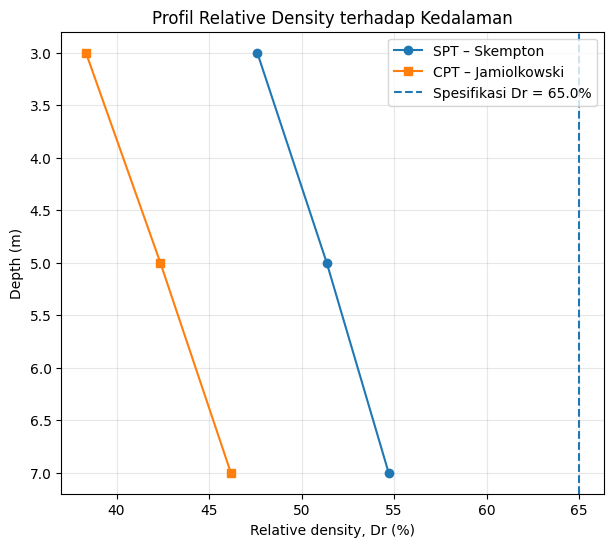

In [ ]:
plot_dr_profile(profile, dr_spec_percent=65.0)


## 7. Unit tests

Tes berikut memeriksa koreksi energi, koreksi overburden, persamaan Skempton, persamaan Jamiolkowski, dan pembentukan profil. Nilai ekspektasi dihitung dari persamaan, bukan dari data proyek.


In [ ]:
# Test 1: energy correction 45% -> N60 = 0.75 N
assert np.isclose(correct_spt_energy(20, 45), 15.0)

# Test 2: Skempton CN fine NC at 100 kPa = 2/(1+100/98.0665)
expected_cn = 2.0 / (1.0 + 100.0 / KPA_PER_KGFCM2)
assert np.isclose(calculate_skempton_cn(100, "nc_fine"), expected_cn)

# Test 3: Dr from (N1)60 = 25 is sqrt(25/60)
res = calculate_dr_skempton(25, 60, 100, soil_case="nc_fine")
assert np.isclose(res["Dr"], np.sqrt(res["N1_60"] / 60.0))

# Test 4: Jamiolkowski dry relation returns expected Dr from direct equation
qc_kpa, sv, k0 = 6000.0, 150.0, 0.5
sigma_m = sv * (1 + 2*k0) / 3
expected_dr = (1/2.96) * np.log((qc_kpa/100.0)/(24.94*(sigma_m/100.0)**0.46))
res_cpt = calculate_dr_jamiolkowski(6.0, sv, k0, saturated=False)
assert np.isclose(res_cpt["Dr"], expected_dr)

# Test 5: saturated correction factor is applied consistently
res_dry = calculate_dr_jamiolkowski(6.0, sv, k0, saturated=False)
res_sat = calculate_dr_jamiolkowski(6.0, sv, k0, saturated=True)
factor = 1 + (-1.87 + 2.32*np.log(6000/np.sqrt(100+sv)))/100
assert np.isclose(res_sat["Dr"], factor*res_dry["Dr"])

# Test 6: profile output converts Dr decimal to percent
p = build_dr_profile([2, 4], dr_spt=[0.5, 0.6], dr_cpt=[0.55, 0.65])
assert np.allclose(p["Dr_SPT_percent"], [50, 60])
assert np.allclose(p["Dr_CPT_percent"], [55, 65])

# Test 7: invalid stress and invalid soil case are rejected
try:
    calculate_skempton_cn(0, "nc_fine")
    raise AssertionError("Expected ValueError for zero stress")
except ValueError:
    pass
try:
    calculate_skempton_cn(100, "unknown")
    raise AssertionError("Expected ValueError for unknown soil case")
except ValueError:
    pass

print("All M3 unit tests passed.")


All M3 unit tests passed.


## 8. Catatan penggunaan dan batasan

1. **SPT:** `energy_ratio` harus berasal dari pengukuran/kalibrasi sistem hammer, bukan ditebak dari tipe hammer saja. Koreksi tambahan untuk panjang batang, diameter lubang, dan sampler dapat diperlukan sesuai prosedur pengujian; modul ini sengaja membatasi koreksi minimum sesuai kebutuhan tugas (energi dan overburden).
2. **Skempton:** pemilihan `soil_case` memerlukan klasifikasi jenis pasir dan status NC/OC. Rumus ringkas Dr pada materi kuliah hanya dipakai pada rentang empiris sekitar 35–85%.
3. **CPT:** persamaan Jamiolkowski sensitif terhadap tegangan efektif rata-rata dan K0. Masukkan K0 yang memiliki dasar geoteknik; jangan menganggap K0=0.5 berlaku universal.
4. **Kondisi jenuh:** koreksi saturasi adalah koreksi empiris tambahan. Pilih `saturated=True` hanya jika kondisi pasir jenuh relevan.
5. **Batas tanah:** korelasi tidak otomatis berlaku untuk tanah berfines tinggi, pasir karbonat, tanah tersementasi, tanah tua, atau kondisi shallow stress di luar kalibrasi.
6. **Profil:** SPT dan CPT dapat memiliki kedalaman uji berbeda. Jika intervalnya berbeda, buat tabel terpisah atau lakukan interpolasi secara sadar; jangan menyamakan titik uji secara otomatis.
7. **Validasi tugas:** notebook ini sudah memiliki unit tests. Validasi numerik wajib terhadap contoh kuliah dan soal UTS nomor 3 belum dimasukkan karena data lengkap soal/kunci UTS dan contoh CPT yang sesuai belum tersedia di file yang diberikan. Jangan menganggap contoh ilustratif sebagai validasi.


## Validation case — published SPT and CPT relative-density correlations

This section performs equation-level numerical checks using published correlations and coefficients. The test inputs are declared explicitly; they are **not represented as a field case or a worked example reported by the authors**.

### A. SPT — Skempton (1986)

Sources:
- Skempton, A. W. (1986). “Standard penetration test procedures and the effects in sands of overburden pressure, relative density, particle size, ageing and overconsolidation.” _Géotechnique_, 36(3), 425–447. The overburden correction equations used by the module are Eqs. (20)–(23), pp. 443–444.
- USACE (2025), _EM 1110-1-1905_, §3-4d, Eq. (3-4), printed p. 29: \(D_R=\sqrt{(N_1)_{60}/C_d}\times100\%\); the manual notes \(C_d\approx60\) for the traditional Skempton/Terzaghi–Peck clean-sand relationship.

Test vector: \(N=20\), \(ER=45\%\), \(\sigma'_{v0}=100\) kPa, normally consolidated fine sand.

\[
N_{60}=20(45/60)=15,\quad
C_N=\frac{2}{1+100/98.0665}=0.99024
\]
\[
(N_1)_{60}=15(0.99024)=14.8536,\quad
D_R=\sqrt{14.8536/60}\times100=49.76\%
\]

### B. CPT — Jamiolkowski et al. (2003)

Source: “Revisiting interpretation of relative density from shallow depth CPTs in sand,” _Canadian Geotechnical Journal_ (2021), §2, Eq. (1). This source reproduces the Jamiolkowski coefficients \(C_0=24.94\), \(C_1=0.46\), \(C_2=2.96\), the mean effective stress definition, and the correlation's applicability limits.

Test vector: \(q_c=6.0\) MPa, \(\sigma'_{v0}=150\) kPa, \(K_0=0.5\), \(p_a=100\) kPa, dry relation.

\[
\sigma'_m=\sigma'_{v0}\frac{1+2K_0}{3}=100\text{ kPa}
\]
\[
D_r=\frac{1}{2.96}\ln\left[
\frac{q_c/p_a}{24.94(\sigma'_m/p_a)^{0.46}}
\right]=0.2966=29.66\%
\]

The test vectors are chosen to verify implementation against the published equations; the cited sources provide the correlations and coefficients, not those particular input values.

In [ ]:
# A. SPT equation-level check — Skempton (1986)
spt_check = calculate_dr_skempton(
    n_field=20.0, energy_ratio=45.0,
    sigma_v_eff_kpa=100.0, soil_case="nc_fine"
)
expected_n60 = 20.0 * 45.0 / 60.0
expected_cn = 2.0 / (1.0 + 100.0 / KPA_PER_KGFCM2)
expected_n1_60 = expected_n60 * expected_cn
expected_dr_spt = (expected_n1_60 / 60.0) ** 0.5 * 100.0

assert abs(spt_check["N60"] - expected_n60) < 1e-10
assert abs(spt_check["CN"] - expected_cn) < 1e-10
assert abs(spt_check["N1_60"] - expected_n1_60) < 1e-10
assert abs(spt_check["Dr_percent"] - expected_dr_spt) < 1e-10

# B. CPT equation-level check — Jamiolkowski et al. (2003) coefficients
cpt_check = calculate_dr_jamiolkowski(
    qc_mpa=6.0, sigma_v_eff_kpa=150.0, k0=0.5,
    saturated=False, atmospheric_pressure_kpa=100.0
)
expected_sigma_m = 150.0 * (1.0 + 2.0*0.5) / 3.0
expected_dr_cpt = (1.0/2.96) * np.log(
    (6000.0/100.0) /
    (24.94 * (expected_sigma_m/100.0)**0.46)
)
assert abs(cpt_check["sigma_m_eff_kpa"] - expected_sigma_m) < 1e-10
assert abs(cpt_check["Dr"] - expected_dr_cpt) < 1e-10

print("M3 published-correlation validation")
print(f"SPT N60                         : {spt_check['N60']:.3f}")
print(f"SPT CN                          : {spt_check['CN']:.5f}")
print(f"SPT (N1)60                      : {spt_check['N1_60']:.4f}")
print(f"SPT Dr                          : {spt_check['Dr_percent']:.2f}%")
print(f"CPT mean effective stress       : {cpt_check['sigma_m_eff_kpa']:.2f} kPa")
print(f"CPT Dr (Jamiolkowski, dry)      : {cpt_check['Dr_percent']:.2f}%")
print("All M3 published-correlation checks passed.")

M3 published-correlation validation
SPT N60                         : 15.000
SPT CN                          : 0.99024
SPT (N1)60                      : 14.8536
SPT Dr                          : 49.76%
CPT mean effective stress       : 100.00 kPa
CPT Dr (Jamiolkowski, dry)      : 29.66%
All M3 published-correlation checks passed.
